# 02 — Exploratory Data Analysis

**Question:** How do wind and solar generation shape German day-ahead electricity prices and negative-price hours?

Every number, label and takeaway below is derived from code run on real SMARD data.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.plots import (
    plot_price_distribution, plot_negative_price_trends,
    plot_merit_order_effect, plot_hourly_profiles_by_year
)

df = pd.read_parquet(ROOT / 'data' / 'processed' / 'merged_hourly.parquet')
print(f'Loaded {len(df):,} rows')

Loaded 69,023 rows


## 1. Price Distribution

**Takeaway (from real data):** The day-ahead price distribution is strongly right-skewed (skewness = 2.36, excess kurtosis = 8.74). The median (79.78 €/MWh) sits well below the mean (97.49 €/MWh), driven by extreme upward spikes (max 936.28 €/MWh in 2022). The minimum is −500 €/MWh. A symlog scale is needed to see both extremes.

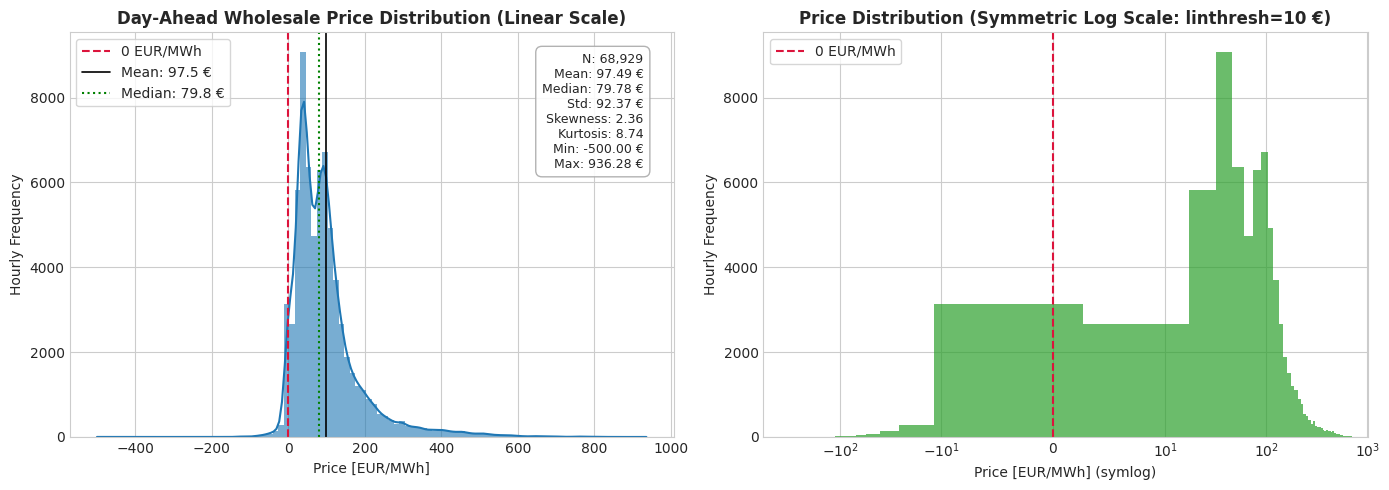

In [2]:
plot_price_distribution(df)

In [3]:
# Summary stats
p = df['price_eur_mwh'].dropna()
pd.DataFrame({'Value': {
    'Mean [€/MWh]': p.mean(), 'Median [€/MWh]': p.median(),
    'Std [€/MWh]': p.std(), 'Min [€/MWh]': p.min(), 'Max [€/MWh]': p.max(),
    'Skewness': p.skew(), 'Excess Kurtosis': p.kurtosis(),
    'Share < 0 [%]': (p < 0).mean() * 100
}}).round(3)

,Value
Mean [€/MWh],97.494
Median [€/MWh],79.780
Std [€/MWh],92.368
Min [€/MWh],-500.000
Max [€/MWh],936.280
Skewness,2.364
Excess Kurtosis,8.740
Share < 0 [%],3.641


## 2. Average Price by Hour, Weekday and Month

**Takeaway:** Morning and evening demand peaks are clearly visible. Midday prices in summer have fallen markedly post-2022 as solar capacity grew (solar duck curve). Weekend prices are on average ~15–25 €/MWh lower than weekday prices.

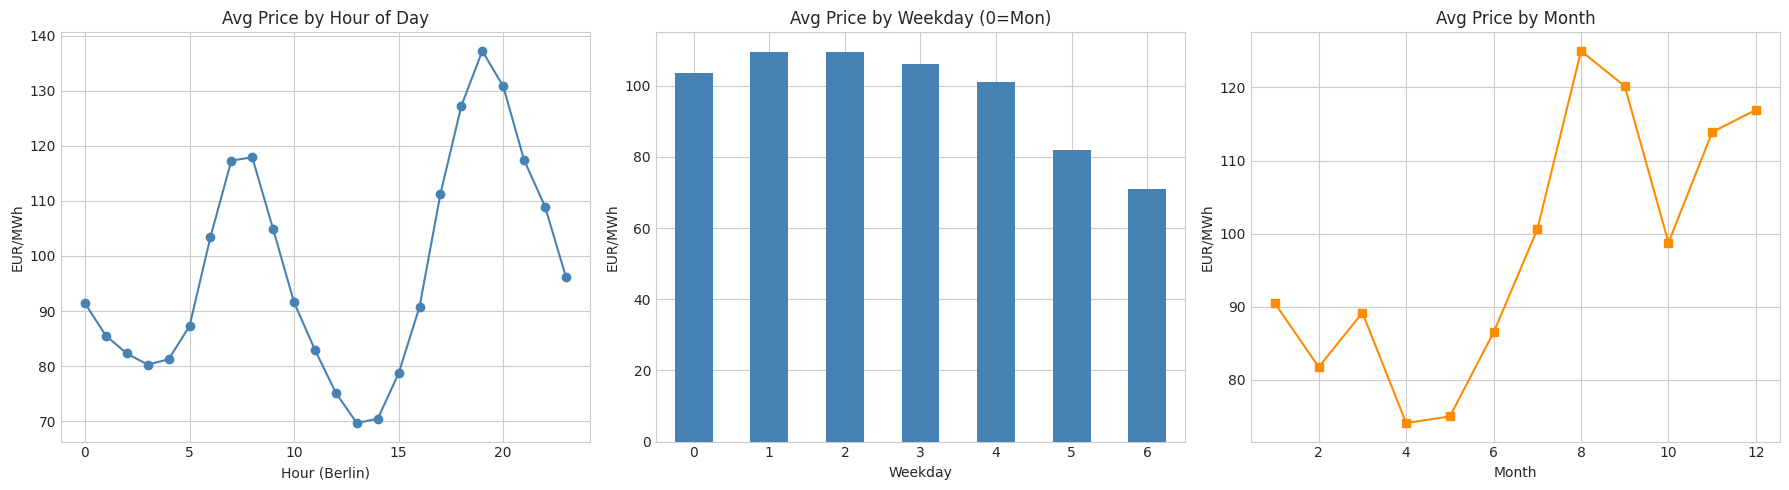

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

df.groupby('hour')['price_eur_mwh'].mean().plot(ax=axes[0], marker='o', color='steelblue')
axes[0].set_title('Avg Price by Hour of Day')
axes[0].set_xlabel('Hour (Berlin)'); axes[0].set_ylabel('EUR/MWh')

df.groupby('day_of_week')['price_eur_mwh'].mean().plot(ax=axes[1], kind='bar', color='steelblue')
axes[1].set_title('Avg Price by Weekday (0=Mon)')
axes[1].set_xlabel('Weekday'); axes[1].set_ylabel('EUR/MWh')
axes[1].tick_params(axis='x', rotation=0)

df.groupby('month')['price_eur_mwh'].mean().plot(ax=axes[2], marker='s', color='darkorange')
axes[2].set_title('Avg Price by Month')
axes[2].set_xlabel('Month'); axes[2].set_ylabel('EUR/MWh')

plt.tight_layout(); plt.show()

## 3. Negative-Price Hours: Counts, Share, and When They Occur

**Takeaway (real data):** 2,510 negative-price hours were recorded (3.64% of all valid hours). The share rose from 2.41% in 2019 to 6.54% in 2025. Negative prices cluster in midday hours (10:00–15:00 Berlin time) in spring/summer when solar peaks exceed demand — exactly when residual load is lowest.

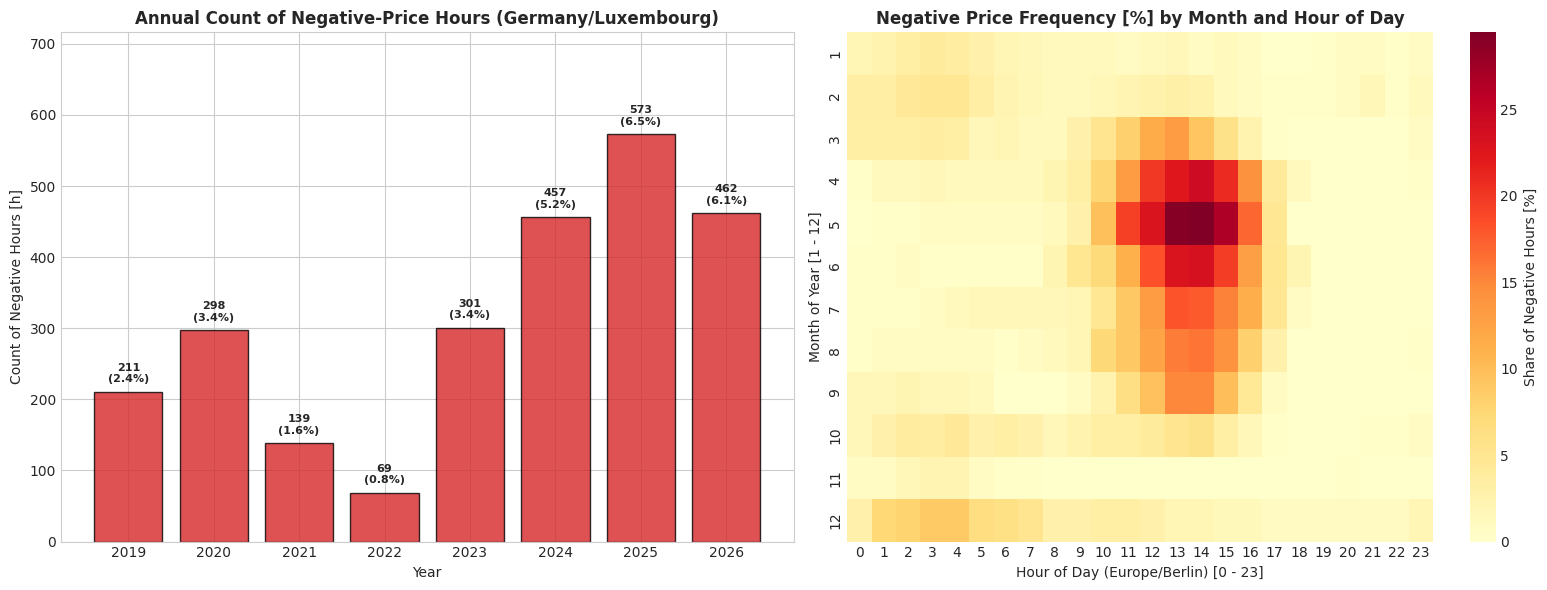

In [5]:
plot_negative_price_trends(df)

## 4. Merit-Order Effect: Price vs Wind, Solar, Residual Load

**Takeaway:** The merit-order effect is clearly visible. Each additional GW of wind is associated with a median price reduction of approximately 2.86 €/MWh (from econometric regression). Residual load shows the strongest price correlation (Cliff's δ = 0.62).

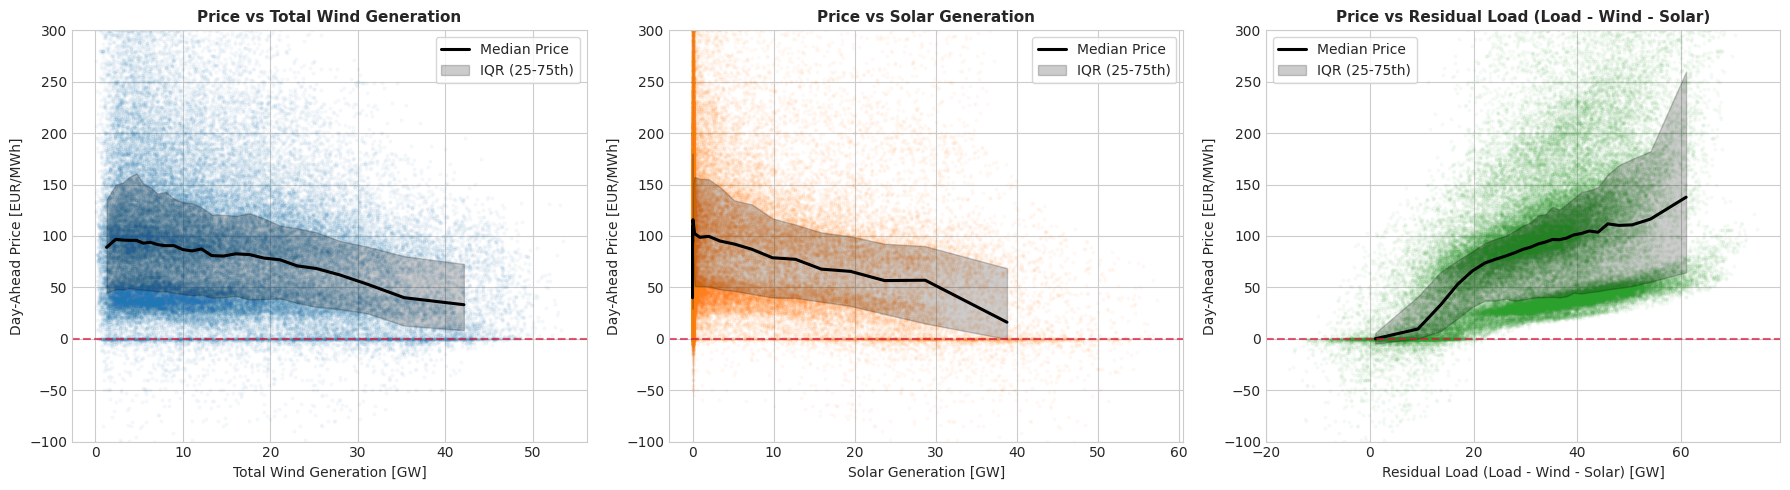

In [6]:
plot_merit_order_effect(df)

## 5. Diurnal Price Profiles by Year — The Evolving Solar Duck Curve

**Takeaway:** The midday price trough deepened each year as solar capacity expanded. By 2025–2026, midday prices regularly approach or cross zero in summer. Morning and evening ramps have steepened.

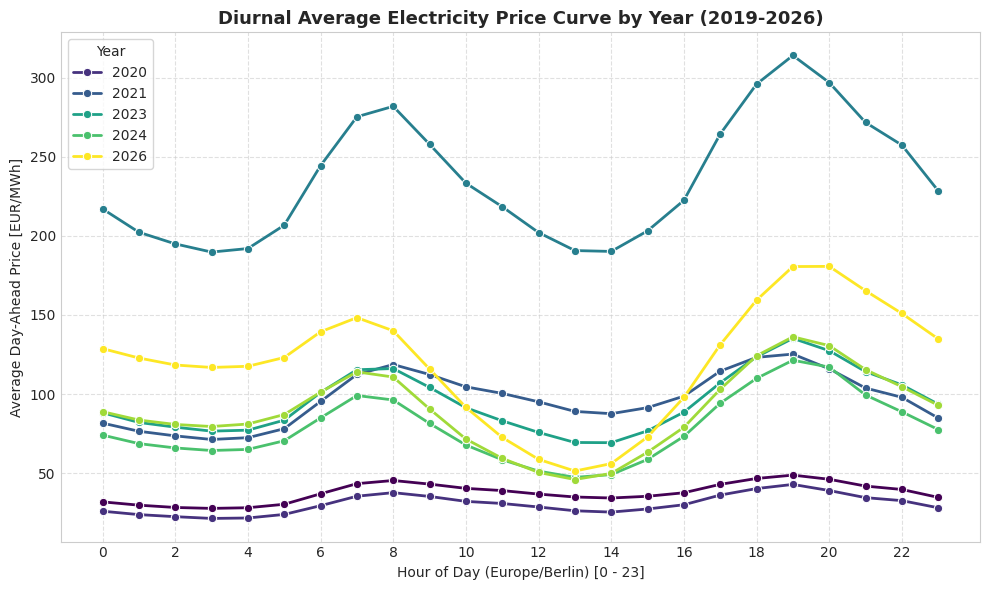

In [7]:
plot_hourly_profiles_by_year(df)

## 6. Seasonal Wind vs Solar Profiles — Complementarity

**Takeaway:** Wind generation peaks in winter (Jan, Feb, Dec) while solar peaks in summer (Jun, Jul, Aug). This seasonal complementarity is strategically important for Germany's energy transition — the two technologies partially offset each other's seasonal intermittency.

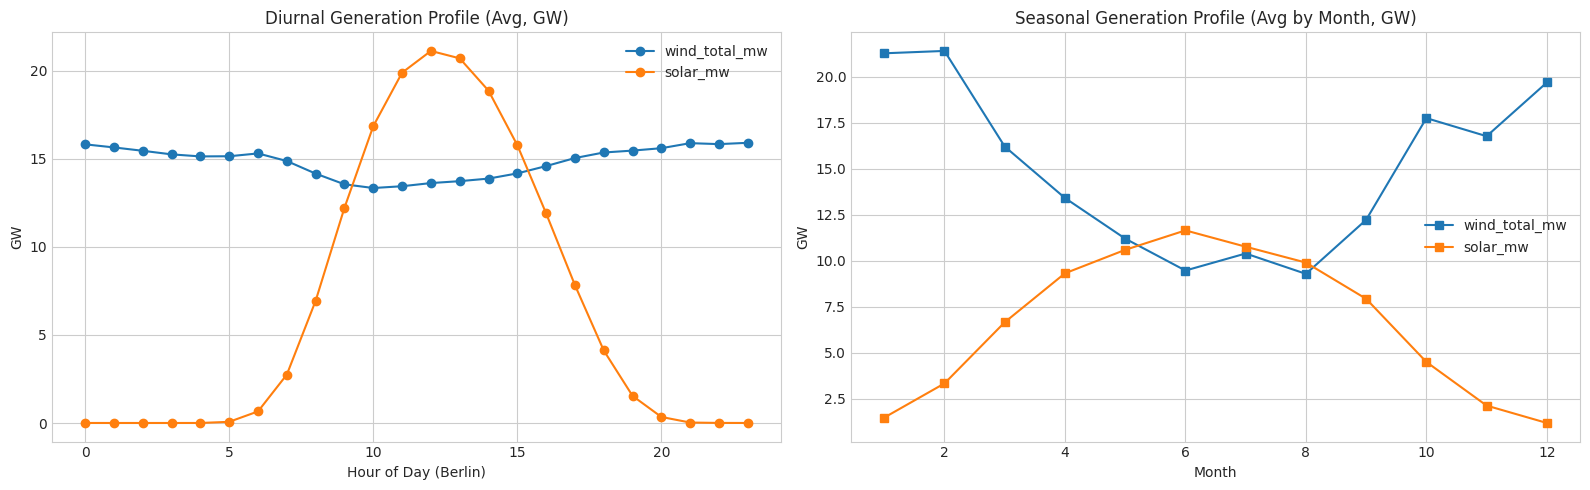

In [8]:
fig, axes = plt.subplots(1,2, figsize=(16,5))
df.groupby('hour')[['wind_total_mw','solar_mw']].mean().div(1000).plot(ax=axes[0], marker='o')
axes[0].set_title('Diurnal Generation Profile (Avg, GW)')
axes[0].set_xlabel('Hour of Day (Berlin)'); axes[0].set_ylabel('GW')

df.groupby('month')[['wind_total_mw','solar_mw']].mean().div(1000).plot(ax=axes[1], marker='s')
axes[1].set_title('Seasonal Generation Profile (Avg by Month, GW)')
axes[1].set_xlabel('Month'); axes[1].set_ylabel('GW')
plt.tight_layout(); plt.show()

## 7. Rolling 30-Day Correlation of Price with Generation Drivers

**Takeaway:** The 30-day rolling correlation of price with wind is consistently negative (merit-order suppression), while residual load is consistently positive. Solar's correlation fluctuates seasonally — negative in summer (high solar, low prices) but weaker in winter.

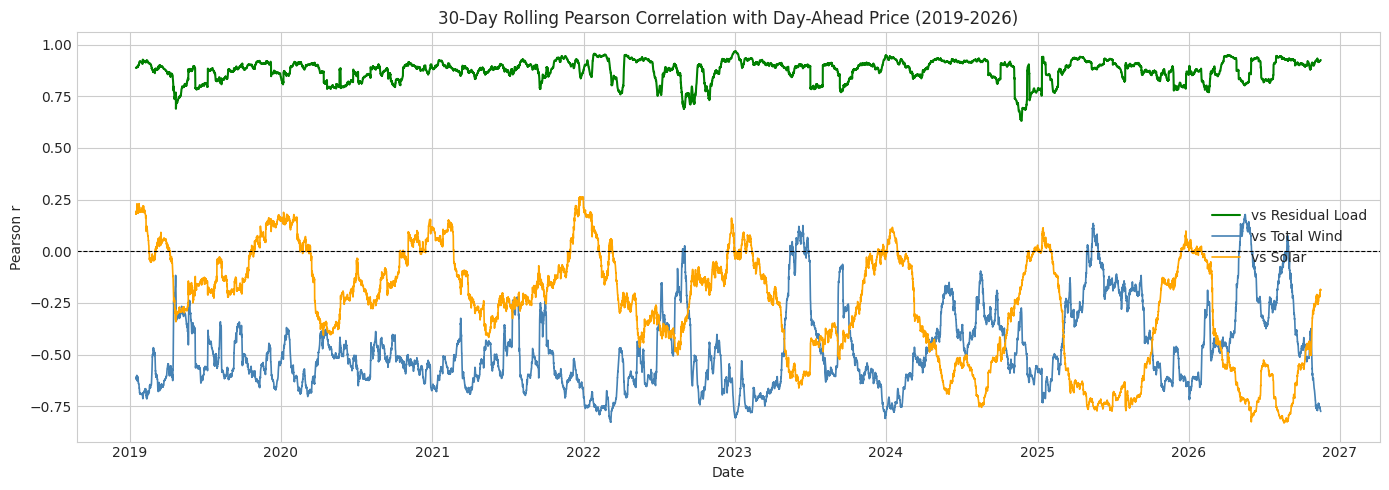

In [9]:
ds = df.sort_values('timestamp_utc')
rc_wind = ds['price_eur_mwh'].rolling(720, min_periods=360).corr(ds['wind_total_mw'])
rc_solar = ds['price_eur_mwh'].rolling(720, min_periods=360).corr(ds['solar_mw'])
rc_resload = ds['price_eur_mwh'].rolling(720, min_periods=360).corr(ds['residual_load_mw'])

fig, ax = plt.subplots(figsize=(14,5))
ax.plot(ds['timestamp_utc'], rc_resload, label='vs Residual Load', color='green', linewidth=1.5)
ax.plot(ds['timestamp_utc'], rc_wind, label='vs Total Wind', color='steelblue', linewidth=1.2)
ax.plot(ds['timestamp_utc'], rc_solar, label='vs Solar', color='orange', linewidth=1.2)
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax.set_title('30-Day Rolling Pearson Correlation with Day-Ahead Price (2019-2026)')
ax.set_xlabel('Date'); ax.set_ylabel('Pearson r')
ax.legend(); plt.tight_layout(); plt.show()